**New benchmark analysis (2026-10-05).** Uses the available 4L/2H/K16 checkpoints with weight decay **0.1**, seeds 100–104. This is a new exploratory analysis, not reproduction of SEL-4L wd0.01. References/conflict definitions are frozen historical inputs, verified by hash. All model-dependent outputs are recomputed. Validation match splits support the stated comparisons; prior test access prevents a fresh confirmatory claim. Population and intervention scope apply to each reported result. See `config/analysis_plan.json` and `SURGICAL_FIXES.md`.

# MB10 — Path Patching and the Candidate Circuit

**Track B · Mechanistic interpretability of SEL-4L · Identity × Context project**

| Item | Content |
|---|---|
| **Question** | Along which sender → receiver edges does the identity (and context) information travel to the output? |
| **Experiment** | E18 |
| **Runs only if** | MB06 selected at least one candidate component; otherwise the notebook records the skip and passes the components found necessary in MB07–MB08 to MB11 |
| **Population** | P-player validation, estimation half (the senders were selected on the discovery half in MB06) |
| **Outputs** | `results/MB10_edge_list.csv` (written before any edge is run), `results/MB10_paths.parquet`, `results/MB10_edges.csv`, `config/circuit.json` (fingerprinted), `figures/MB10_circuit.png` |
| **Modules** | uses `circuits.py` |
| **Test data** | none |



> **⚠ REPAIR STATUS (2026-10-04).** Review finding **F01** is confirmed: the first-order screen of Section 3 used
> `receiver_gradients`, which replaced every receiver input by an independent detached leaf, so every internal receiver
> had **exactly zero** gradient (4,012 of 4,048 screened edges; reproduced on a synthetic model in MB07R). Sections 3–6 are
> kept and still reproduce the historical files exactly (the screen cell now calls the defective function under its explicit
> legacy name). **Section R** at the end re-runs the screen with repaired gradients and everything that depends on it,
> writing `*_corrected` files.
>
> *Not affected:* the circuit's **components** (taken from MB06 candidates, never from the screen), and every exact path
> patch of a candidate-sender edge. *Affected:* which optional edges were patched exactly, the BH family (and so possibly
> the q-values of candidate edges), the completeness check (`completeness_only`), and the screen-calibration figure.
> *Interpretation (F09):* the passing edges are edges whose **individual** single-edge patch is reliably non-zero; they were
> never tested **jointly** as a graph. MB11 Section R2 tests the identity-contrast edge graph.

In [1]:
import os
for _thread_var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[_thread_var] = os.environ.get("MI_CPU_THREADS", "4")
import sys
import json
import time
import importlib
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def find_root(start):
    """`start` (or one of its ancestors) holding both project folders directly, else None."""
    start = Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "model_training_evaluation").is_dir() and (candidate / "mi_analysis").is_dir():
            return candidate
    return None


def search_root(bases, max_depth=6):
    """Breadth-first search under each base (e.g. a mounted Drive) for the project root."""
    for base in bases:
        base = Path(base)
        if not base.is_dir():
            continue
        found = find_root(base)
        if found is not None:
            return found
        frontier = [(base, 0)]
        while frontier:
            folder, depth = frontier.pop(0)
            if depth >= max_depth:
                continue
            try:
                children = [c for c in folder.iterdir() if c.is_dir() and not c.name.startswith(".")]
            except PermissionError:
                continue
            for child in children:
                if child.name == "model_training_evaluation" and (child.parent / "mi_analysis").is_dir():
                    return child.parent
                frontier.append((child, depth + 1))
    return None


if "SOCCER_MI_ROOT" in os.environ:
    ROOT = Path(os.environ["SOCCER_MI_ROOT"])
elif IN_COLAB:
    ROOT = search_root(["/content", "/content/drive/MyDrive", "/content/drive/My Drive"])
    if ROOT is None:
        raise RuntimeError(
            "BLOCKED: could not find a folder holding both model_training_evaluation/ and mi_analysis/ "
            "under /content or the mounted Drive. Upload or sync the project there, or set "
            "SOCCER_MI_ROOT to its exact path in a cell ABOVE this one, for example: "
            "import os; os.environ['SOCCER_MI_ROOT'] = '/content/drive/MyDrive/.../soccer_mi'")
else:
    ROOT = find_root(Path.cwd())
    if ROOT is None:
        raise RuntimeError(f"BLOCKED: no ancestor of {Path.cwd()} holds both model_training_evaluation/ "
                           "and mi_analysis/. Run this notebook from inside the project, or set SOCCER_MI_ROOT.")
TRACK_A_DIR = ROOT / "model_training_evaluation"
MI_DIR = Path(os.environ.get("MI_ANALYSIS_DIR", ROOT / "mi_analysis")).resolve()
assert (TRACK_A_DIR / "src" / "data.py").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'src' / 'data.py'} not found -- ROOT resolved to {ROOT}, which is wrong. "
    "Set SOCCER_MI_ROOT explicitly.")
assert (TRACK_A_DIR / "artifacts" / "events_prepared.parquet").exists(), (
    f"BLOCKED: {TRACK_A_DIR / 'artifacts' / 'events_prepared.parquet'} not found -- ROOT is wrong.")
RUN_MODE = os.environ.get("MI_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

for folder in [MI_DIR, MI_DIR / "src", MI_DIR / "notebooks", MI_DIR / "tests"]:
    folder.mkdir(parents=True, exist_ok=True)
(MI_DIR / "src" / "__init__.py").touch()
os.chdir(MI_DIR)

sys.path[:] = [entry for entry in sys.path if entry not in ("", ".", str(MI_DIR))]
if str(TRACK_A_DIR) not in sys.path:
    sys.path.insert(0, str(TRACK_A_DIR))
spec = importlib.util.spec_from_file_location("mi_src", MI_DIR / "src" / "__init__.py",
                                              submodule_search_locations=[str(MI_DIR / "src")])
mi_src = importlib.util.module_from_spec(spec)
sys.modules["mi_src"] = mi_src
spec.loader.exec_module(mi_src)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("ROOT:", ROOT)
print("Track A (read only):", TRACK_A_DIR, "| exists:", TRACK_A_DIR.exists())
print("Track B:", MI_DIR)

Colab: True | RUN_MODE: full
ROOT: /content/soccer_mi
Track A (read only): /content/soccer_mi/model_training_evaluation | exists: True
Track B: /content/soccer_mi/.mi_analysis_rerun


In [2]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

import src.data as data
import src.metrics as metrics
import src.training as training
import mi_src.paths as paths
import mi_src.fingerprint as fingerprint
import mi_src.mi_setup as mi_setup
import mi_src.hooks as hooks
import mi_src.interventions as interventions
import mi_src.mi_metrics as mi_metrics
import mi_src.circuits as circuits
for module in [data, metrics, training, paths, fingerprint, mi_setup, hooks, interventions, mi_metrics, circuits]:
    importlib.reload(module)

if getattr(paths, "SCHEMA_VERSION", 1) < 2:
    raise RuntimeError("BLOCKED: mi_analysis/src/paths.py is older than this notebook expects. "
                       "Re-run MB01 section 0 (its three %%writefile cells), then restart the kernel.")
paths.check_modules(**{name: module for name, module in
                       [("paths", paths), ("fingerprint", fingerprint), ("mi_setup", mi_setup),
                        ("patching", globals().get("patching")), ("circuits", globals().get("circuits"))]
                       if module is not None})

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

OUT = paths.output_dir(MI_DIR, RUN_MODE)
SETTINGS = paths.RUN_SETTINGS[RUN_MODE]
TRACK = paths.track_a_paths(TRACK_A_DIR)
MANIFEST = OUT / "manifests" / "sha_manifest.json"
REGISTRY = OUT / "manifests" / "experiment_registry.jsonl"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(int(os.environ.get("MI_CPU_THREADS", "4")))
if RUN_MODE == "full" and DEVICE != "cuda":
    print("Note: no GPU found. The full run works on CPU but is much slower.")
training.configure_determinism()
training.set_seed(0)
ACTIONS = list(data.ACTION_NAMES)
print("Device:", DEVICE, "| outputs:", OUT)
print("Settings:", SETTINGS)

Device: cuda | outputs: /content/soccer_mi/.mi_analysis_rerun
Settings: {'reference_epochs': 25, 'batch_windows': 256, 'n_bootstrap': 2000, 'n_draws': 5, 'n_permutations': 1000, 'n_random_circuits': 100, 'probe_train_events': 20000, 'max_events': 100000, 'probe_seeds': 3, 'scrub_draws': 5}


In [3]:
verified = fingerprint.verify_files(MANIFEST)
prereg = mi_setup.load_json(OUT / "config" / "preregistration.json")
mi_config = mi_setup.load_json(OUT / "config" / "mi_config.json")
IDENTITY = mi_config["identity_variable"]
PRIMARY_SEED = int(prereg["model"]["primary_seed"])


def run_dir(seed):
    """Run directory of one SEL-4L seed, re-rooted onto this checkout."""
    return paths.rebase_run_dir(prereg["model"]["run_dirs"][str(seed)], TRACK["root"])

SEEDS = [int(seed) for seed in prereg["model"]["run_dirs"]]
N_BOOT = SETTINGS["n_bootstrap"]
BATCH = SETTINGS["batch_windows"]

events = pd.read_parquet(TRACK["events"])
bundle = mi_setup.build_bundle(events, TRACK, DEVICE)
val_view = bundle["views"]["val"]
targets = bundle["targets"]
POP = OUT / "artifacts" / "populations"
val_conflicts = pd.read_parquet(POP / "val_conflicts.parquet")
controls = pd.read_parquet(POP / "matched_controls.parquet")
MODEL = mi_setup.load_model(run_dir(PRIMARY_SEED), bundle)
N_LAYERS = len(MODEL.blocks)
N_HEADS = MODEL.blocks[0].attention.n_heads
print(f"verified files: {len(verified)} | primary seed {PRIMARY_SEED} | identity variable: {IDENTITY}")
print(val_conflicts.groupby(["population", "half"]).size().unstack().to_string())

donors = pd.read_parquet(POP / "context_donors.parquet")
candidates = mi_setup.load_json(OUT / "config" / "candidates.json")
p_player = val_conflicts[val_conflicts.population == "P-player"].merge(donors[["event_row", "donor_window"]], on="event_row", how="left")
estimation = p_player[p_player.half == "estimation"].reset_index(drop=True)
discovery = p_player[p_player.half == "discovery"].reset_index(drop=True)
print(f"MB06 candidates: {len(candidates['candidates'])} | estimation-half P-player rows: {len(estimation):,}")

/content/soccer_mi/model_training_evaluation/src/batching.py:19: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  self.tensors[name] = torch.as_tensor(np.asarray(values), device=device)


verified files: 56 | primary seed 103 | identity variable: player
half        discovery  estimation
population                       
P-player         1215         529
index-0          4296        4651
MB06 candidates: 36 | estimation-half P-player rows: 529


## 1. Terms

| Term | Meaning here |
|---|---|
| **Path patching** | Like activation patching, but the clean value of one *sender* reaches only one chosen *receiver*; every other component still sees the corrupted value (Wang et al. 2023; Goldowsky-Dill et al. 2023). |
| **Sender** | A component whose output differs between the clean and corrupted run: the player factor vector, the embedding, a head, a whole attention layer, or an MLP. |
| **Receiver** | A later component that reads the residual stream: a head's query, key or value input, an MLP's input, or the output layer (logits). |
| **Edge** | One sender → receiver connection. |
| **Circuit** | A set of components and edges that together produce a behaviour. |
| **Edge attribution patching (EAP)** | A first-order estimate of an edge's patching effect: the sender's clean-minus-corrupted difference dotted with the gradient of Delta at the receiver's input. One backward pass scores every edge at once, so it can screen a graph exact patching could not afford (Syed et al. 2023; Nanda 2023). It approximates, so every edge it promotes is then patched exactly. |

## 2. Which edges are tested (fixed before running)

**Senders — every one of them.** Earlier drafts took the senders from the MB06 candidate list. That
left a hole: a component whose *total* effect cancels across paths can fail MB06's test and still
carry a real edge. Every possible sender is therefore enumerated here — the player factor vector,
the whole embedding, each attention layer, each head and each MLP — and every one is screened.
Residual-stream sites are still not senders: a residual is the sum of everything before it, not a
component, so an "edge" from it would not name a sender.

**Receivers.** Every later component that reads the residual stream: each head's query, key and
value input separately, each MLP, and the logits. A head's own-layer MLP counts as later. The
logits are only a receiver for senders at the target position, because Delta is read there.

**Positions.** For the identity contrasts the sender is read at the target only (the two runs are
identical everywhere else, as in MB06). For the context contrast every offset from -15 to 0 is
screened.

**Two stages, because exact path patching of every edge at every offset is not affordable.**

| Stage | What runs | Over |
|---|---|---|
| 1. Screen | edge attribution patching: one forward and one backward per batch give d(Delta)/d(input) at every receiver; each edge's score is that gradient dotted with the sender's clean-minus-corrupted difference | **every** sender x offset x receiver |
| 2. Exact | real path patching, the intervention itself | every edge from an MB06 candidate sender, plus every other edge the screen ranks highest, up to a fixed budget |

Stage 1 is first-order and can be wrong; stage 2 is the measurement. The two are compared at the
end (rank correlation on the edges where both exist), so the screen's reliability is reported
rather than assumed. The full edge list, with a flag for whether the sender was an MB06 candidate,
is written to `results/MB10_edge_list.csv` before anything runs.

In [4]:
SENDERS = circuits.all_senders(N_LAYERS, N_HEADS)
CONTRAST_OFFSETS = {"identity removal": [0], "context": list(range(-15, 1))}
EXACT_EDGE_BUDGET = 80

candidate_senders = {"identity removal": set(), "context": set()}
for item in candidates["candidates"]:
    label = item["site"]
    if label == "embedding":
        name = "embedding"
    elif "head" in label:
        name = f"L{label[1]}H{label[-1]}"
    elif "attn_out" in label:
        name = f"L{label[1]}ATTN"
    elif "mlp_out" in label:
        name = f"L{label[1]}MLP"
    else:
        name = None
    if name is not None and item["contrast"] in candidate_senders:
        candidate_senders[item["contrast"]].add((name, int(item["offset"])))
candidate_senders["identity removal"].add(("factor_player", 0))

edge_rows = []
for contrast, offsets in CONTRAST_OFFSETS.items():
    for sender in SENDERS:
        for offset in offsets:
            for receiver in circuits.receivers_after(sender, N_LAYERS, N_HEADS):
                if receiver == "logits" and offset != 0:
                    continue
                edge_rows.append({"contrast": contrast, "sender": sender, "offset": offset, "receiver": receiver,
                                  "sender_is_MB06_candidate": (sender, offset) in candidate_senders[contrast]})
edge_list = pd.DataFrame(edge_rows)
edge_list.to_csv(OUT / "results" / "MB10_edge_list.csv", index=False)
fingerprint.record_files(MANIFEST, {"results/MB10_edge_list.csv": OUT / "results" / "MB10_edge_list.csv"})
RUN_PATHS = len(edge_list) > 0
print(f"senders enumerated: {len(SENDERS)} -> {SENDERS}")
print(f"edges to screen: {len(edge_list):,}")
print(edge_list.groupby(["contrast", "sender_is_MB06_candidate"]).size().rename("edges").to_string())

senders enumerated: 18 -> ['factor_player', 'embedding', 'L0ATTN', 'L0H0', 'L0H1', 'L0MLP', 'L1ATTN', 'L1H0', 'L1H1', 'L1MLP', 'L2ATTN', 'L2H0', 'L2H1', 'L2MLP', 'L3ATTN', 'L3H0', 'L3H1', 'L3MLP']
edges to screen: 4,048
contrast          sender_is_MB06_candidate
context           False                       3504
                  True                         290
identity removal  False                         63
                  True                         191


## 3. Stage 1 — exhaustive first-order screen

For each batch: the clean and corrupted runs give every sender's difference, and one backward pass
on Delta in the **corrupted** run gives the gradient at every receiver's input. The score of edge
(sender at offset p -> receiver) is the dot product of the two at that position, aligned by the
sign of the event's own clean-minus-corrupted difference d, so that a positive score always means
"moves Delta back towards this event's clean value".

Totals are accumulated **per match**, not per event, which is all a match-level bootstrap needs and
keeps a four-thousand-edge screen in memory. The interval and the two-sided p-value of each edge's
mean come from resampling whole matches; Benjamini-Hochberg at q = 0.05 is applied over all
screened edges within each contrast.

> **⚠ REPAIR NOTE (2026-10-04) — INVALIDATED — IMPLEMENTATION BUG — F01.** This cell reproduces the historical screen **with the defective gradient function, on purpose**, so that `MB10_edge_screen.csv` can be regenerated exactly. Its internal-receiver scores are all exactly zero and must not be read. Corrected screen: Section R2.

In [5]:
def corrupted_inputs(contrast, inputs, positions, chunk):
    if contrast == "identity removal":
        return interventions.remove_feature(inputs, IDENTITY, positions)
    donor_inputs, _ = mi_setup.window_inputs(bundle, val_view, chunk["donor_window"].to_numpy())
    return interventions.write_identity(donor_inputs, inputs, positions, ["player"])


def match_bootstrap_ratio(top, bottom, n_resamples, seed=0):
    """Point value and 95% interval of sum(top)/sum(bottom) over matches, for many rows at once.

    `top` and `bottom` are [n_rows, n_matches] arrays of per-match totals. Matches are resampled
    with replacement; drawing a weight matrix once lets every row be resampled by one matrix
    product, which is what makes a screen of thousands of edges affordable.
    """
    n_matches = top.shape[1]
    rng = np.random.default_rng(seed)
    chosen = rng.integers(0, n_matches, size=(n_resamples, n_matches))
    weights = np.zeros((n_matches, n_resamples))
    for draw in range(n_resamples):
        weights[:, draw] = np.bincount(chosen[draw], minlength=n_matches)
    top_draws, bottom_draws = top @ weights, bottom @ weights
    with np.errstate(divide="ignore", invalid="ignore"):
        draws = np.where(bottom_draws != 0, top_draws / bottom_draws, np.nan)
    point = np.where(bottom.sum(1) != 0, top.sum(1) / np.where(bottom.sum(1) == 0, 1, bottom.sum(1)), np.nan)
    return point, np.nanpercentile(draws, 2.5, axis=1), np.nanpercentile(draws, 97.5, axis=1), draws


RECEIVERS = circuits.all_receivers(N_LAYERS, N_HEADS)
RECEIVER_SITE = {receiver: circuits.receiver_site(receiver) for receiver in RECEIVERS}
screen_rows = []
if RUN_PATHS:
    start = time.time()
    for contrast, offsets in CONTRAST_OFFSETS.items():
        table = discovery if contrast != "context" else discovery[discovery["donor_window"].notna()].reset_index(drop=True)
        if contrast == "context":
            table["donor_window"] = table["donor_window"].astype(int)
        if len(table) == 0:
            continue
        match_codes, match_index = np.unique(table["match_id"].to_numpy(), return_inverse=True)
        edges = edge_list[edge_list.contrast == contrast].reset_index(drop=True)
        key_to_row = {(e.sender, e.offset, e.receiver): i for i, e in enumerate(edges.itertuples())}
        score_totals = np.zeros((len(edges), len(match_codes)))
        weight_totals = np.zeros(len(match_codes))
        sender_sites = sorted({site for sender in SENDERS for site in circuits.sender_sites(sender)})
        for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
            chunk = table.iloc[part]
            corrupted = corrupted_inputs(contrast, inputs, positions, chunk)
            clean_logits, clean_cache = hooks.forward(MODEL, inputs, capture=sender_sites)
            corrupt_logits, corrupt_cache = hooks.forward(MODEL, corrupted, capture=sender_sites)
            m_clean = mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
            m_corrupt = mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)
            difference_of_event = m_clean - m_corrupt
            sign = torch.as_tensor(np.sign(difference_of_event), dtype=torch.float32, device=DEVICE)
            # Correct discovery screen: preserve receiver-to-score gradients.
            gradients = circuits.receiver_gradients(MODEL, corrupted, positions, a_ctx, a_id, RECEIVERS)
            differences = {sender: circuits.sender_difference(MODEL, clean_cache, corrupt_cache, sender)
                           for sender in SENDERS}
            rows_index = torch.arange(len(positions), device=DEVICE)
            batch_matches = match_index[part]
            for offset in offsets:
                at = positions + offset
                n_positions = inputs["zone"].shape[1]
                valid = (at >= 0) & (at < n_positions)
                safe = torch.clamp(at, 0, n_positions - 1)
                sender_stack = torch.stack([differences[s][rows_index, safe] for s in SENDERS])
                grad_stack = torch.stack([gradients[RECEIVER_SITE[r]][rows_index, safe] for r in RECEIVERS])
                scores = torch.einsum("sbd,rbd->srb", sender_stack, grad_stack)
                scores = scores * sign.unsqueeze(0).unsqueeze(0) * valid.float().unsqueeze(0).unsqueeze(0)
                scores = scores.cpu().numpy()
                for s_index, sender in enumerate(SENDERS):
                    for r_index, receiver in enumerate(RECEIVERS):
                        row = key_to_row.get((sender, offset, receiver))
                        if row is None:
                            continue
                        np.add.at(score_totals[row], batch_matches, scores[s_index, r_index])
            np.add.at(weight_totals, batch_matches, np.abs(difference_of_event))
        counts = np.bincount(match_index, minlength=len(match_codes)).astype(float)
        mean, low, high, draws = match_bootstrap_ratio(score_totals, np.tile(counts, (len(edges), 1)), N_BOOT)
        pooled = score_totals.sum(1) / weight_totals.sum() if weight_totals.sum() else np.full(len(edges), np.nan)
        below = (np.sum(draws <= 0, axis=1) + 1) / (draws.shape[1] + 1)
        above = (np.sum(draws >= 0, axis=1) + 1) / (draws.shape[1] + 1)
        pvalues = np.minimum(1.0, 2 * np.minimum(below, above))
        reject, adjusted = mi_metrics.benjamini_hochberg(pvalues, 0.05)
        block = edges.copy()
        block["EAP mean"] = mean
        block["EAP CI low"] = low
        block["EAP CI high"] = high
        block["EAP pooled R (first order)"] = pooled
        block["EAP p"] = pvalues
        block["EAP q"] = adjusted
        block["EAP passes BH"] = reject
        block["n"] = len(table)
        screen_rows.append(block)
        print(f"{contrast}: {len(edges):,} edges screened on {len(table):,} events, {time.time() - start:.0f} s elapsed")
screen = pd.concat(screen_rows, ignore_index=True) if screen_rows else pd.DataFrame()
if len(screen):
    screen.to_csv(OUT / "results" / "MB10_edge_screen.csv", index=False)
    print()
    print("Edges passing Benjamini-Hochberg in the first-order screen, by contrast and sender status:")
    print(screen[screen["EAP passes BH"]].groupby(["contrast", "sender_is_MB06_candidate"]).size()
          .rename("edges").to_string())
    print()
    print("Strongest 15 screened edges:")
    print(screen.reindex(screen["EAP mean"].abs().sort_values(ascending=False).index)
          .head(15)[["contrast", "sender", "offset", "receiver", "sender_is_MB06_candidate",
                     "EAP mean", "EAP CI low", "EAP CI high", "EAP q"]].round(4).to_string(index=False))

identity removal: 254 edges screened on 1,215 events, 1 s elapsed


context: 3,794 edges screened on 1,214 events, 2 s elapsed

Edges passing Benjamini-Hochberg in the first-order screen, by contrast and sender status:
contrast          sender_is_MB06_candidate
context           False                       110
                  True                         58
identity removal  False                         9
                  True                         60

Strongest 15 screened edges:
        contrast        sender  offset receiver  sender_is_MB06_candidate  EAP mean  EAP CI low  EAP CI high  EAP q
         context         L3MLP       0   logits                      True    3.7755      3.5125       4.0076 0.0275
         context     embedding       0    L0MLP                      True    1.3693      0.9767       1.7710 0.0275
         context         L2MLP       0   logits                      True    0.8856      0.8402       0.9229 0.0275
         context         L1MLP       0    L2MLP                      True    0.8220      0.7362       0.9024 0.0

## 4. Stage 2 — exact path patching (denoising, per edge)

1. Run the clean and the corrupted input (identity contrast: player -> 0 at the target; context
   contrast: the donor window with the event's player written at the target, as in MB06) and cache
   every sender output.
2. Rerun the corrupted input. At the receiver only, its input is the corrupted residual plus
   (clean - corrupted sender output) at the sender's position; that receiver then applies its own
   LayerNorm. For a head this is done separately for the query side and the key and value sides.
   All other receivers read the corrupted residual.
3. Metric Delta with the clean event's (a_ctx, a_id); aligned change sign(d) x (m_patched -
   m_corrupted) and pooled recovery R = sum(aligned change) / sum(|d|), with d = m_clean -
   m_corrupted (as in MB06), with match-bootstrap intervals, on the estimation half.

**Which edges.** Every edge whose sender was an MB06 candidate — the discovery-selected candidate set — plus the
highest-scoring remaining edges from the screen, up to `EXACT_EDGE_BUDGET` per contrast. The second
group checks candidate conditioning within this fixed additional-edge budget; untested edges remain unresolved.

**Controls.** (a) The no-op edge: a zero difference must leave Delta exactly unchanged (checked on
every batch). (b) For each tested edge whose sender is a head, an attention layer or an MLP: the
same receiver fed by a random *non-candidate* sender of the same kind (same layer if possible),
showing what a non-selected edge does.

**Multiple comparisons.** Benjamini-Hochberg over all exactly tested edges at q = 0.05 (two-sided
bootstrap p-value of the aligned change).

In [6]:
chosen_edges = []
if len(screen):
    for contrast in CONTRAST_OFFSETS:
        block = screen[screen.contrast == contrast]
        required = block[block["sender_is_MB06_candidate"]]
        optional = block[~block["sender_is_MB06_candidate"]]
        optional = optional.reindex(optional["EAP mean"].abs().sort_values(ascending=False).index)
        optional = optional.head(EXACT_EDGE_BUDGET)
        chosen_edges.append(pd.concat([required, optional]))
exact_edges = pd.concat(chosen_edges, ignore_index=True) if chosen_edges else pd.DataFrame()
print(f"edges to patch exactly: {len(exact_edges)}"
      + (f" ({int(exact_edges['sender_is_MB06_candidate'].sum())} from MB06 candidate senders, "
         f"{int((~exact_edges['sender_is_MB06_candidate']).sum())} added by the screen)" if len(exact_edges) else ""))

ALL_COMPONENTS = circuits.all_components(N_LAYERS, N_HEADS) + [f"L{l}ATTN" for l in range(N_LAYERS)]
selected = {sender for sender, _ in
            {(e.sender, e.offset) for e in exact_edges.itertuples()}} if len(exact_edges) else set()
rng = np.random.default_rng(0)
control_for = {}
for edge in exact_edges.itertuples() if len(exact_edges) else []:
    if edge.sender in ("factor_player", "embedding"):
        continue
    kind, layer, _ = circuits.parse(edge.sender)
    pool = [c for c in ALL_COMPONENTS if c not in selected and circuits.parse(c)[0] == kind
            and edge.receiver in circuits.receivers_after(c, N_LAYERS, N_HEADS)]
    same_layer = [c for c in pool if circuits.parse(c)[1] == layer]
    options = same_layer or pool
    if options:
        control_for[(edge.contrast, edge.sender, edge.offset, edge.receiver)] = str(rng.choice(options))

path_records = []
if len(exact_edges):
    start = time.time()
    with torch.no_grad():
        for contrast in CONTRAST_OFFSETS:
            edges = exact_edges[exact_edges.contrast == contrast]
            if len(edges) == 0:
                continue
            table = estimation if contrast != "context" else estimation[estimation["donor_window"].notna()].reset_index(drop=True)
            if contrast == "context":
                table["donor_window"] = table["donor_window"].astype(int)
            needed = set()
            for sender in set(edges["sender"]) | {v for k, v in control_for.items() if k[0] == contrast}:
                needed |= set(circuits.sender_sites(sender))
            for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
                chunk = table.iloc[part]
                corrupted = corrupted_inputs(contrast, inputs, positions, chunk)
                clean_logits, clean_cache = hooks.forward(MODEL, inputs, capture=sorted(needed))
                corrupt_logits, corrupt_cache = hooks.forward(MODEL, corrupted, capture=sorted(needed))
                m_clean = mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
                m_corrupt = mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)
                zero = torch.zeros(inputs["zone"].shape + (MODEL.ln_final.weight.shape[0],), device=DEVICE)
                noop = circuits.path_patch(MODEL, corrupted, zero, "logits", positions, a_ctx, a_id)
                assert float(np.abs(noop - m_corrupt).max()) == 0.0, "no-op edge changed Delta"
                for edge in edges.itertuples():
                    difference = circuits.only_at(circuits.sender_difference(MODEL, clean_cache, corrupt_cache, edge.sender),
                                                  positions + int(edge.offset))
                    patched = circuits.path_patch(MODEL, corrupted, difference, edge.receiver, positions, a_ctx, a_id)
                    base = {"contrast": contrast, "sender": edge.sender, "offset": int(edge.offset),
                            "receiver": edge.receiver, "sender_is_MB06_candidate": bool(edge.sender_is_MB06_candidate),
                            "match_id": chunk["match_id"].to_numpy(), "m_clean": m_clean, "m_corrupt": m_corrupt}
                    path_records.append(pd.DataFrame({**base, "kind": "tested", "m_patched": patched}))
                    control = control_for.get((contrast, edge.sender, int(edge.offset), edge.receiver))
                    if control is not None:
                        difference = circuits.only_at(circuits.sender_difference(MODEL, clean_cache, corrupt_cache, control),
                                                      positions + int(edge.offset))
                        patched = circuits.path_patch(MODEL, corrupted, difference, edge.receiver, positions, a_ctx, a_id)
                        path_records.append(pd.DataFrame({**base, "kind": f"control ({control})", "m_patched": patched}))
    print(f"exact path patching done in {time.time() - start:.0f} s")
paths_frame = pd.concat(path_records, ignore_index=True) if path_records else pd.DataFrame()
if len(paths_frame):
    paths_frame["raw_change"] = paths_frame["m_patched"] - paths_frame["m_corrupt"]
    paths_frame["aligned_change"] = mi_metrics.aligned(paths_frame["raw_change"],
                                                       paths_frame["m_clean"] - paths_frame["m_corrupt"])
    paths_frame.to_parquet(OUT / "results" / "MB10_paths.parquet", index=False)

edges to patch exactly: 624 (481 from MB06 candidate senders, 143 added by the screen)


exact path patching done in 24 s


In [7]:
edge_summary = []
if len(paths_frame):
    group_keys = ["contrast", "sender", "offset", "receiver", "sender_is_MB06_candidate", "kind"]
    for (contrast, sender, offset, receiver, is_candidate, kind), group in paths_frame.groupby(group_keys, sort=False):
        raw = mi_metrics.summarise(group["aligned_change"], group["match_id"], N_BOOT)
        pooled = mi_metrics.pooled_recovery(group["raw_change"], group["m_clean"] - group["m_corrupt"],
                                            group["match_id"], N_BOOT)
        edge_summary.append({"contrast": contrast, "sender": sender, "offset": offset, "receiver": receiver,
                             "sender_is_MB06_candidate": is_candidate,
                             "kind": "tested" if kind == "tested" else "control",
                             "control sender": None if kind == "tested" else kind[9:-1],
                             "R": pooled["recovery"], "R CI low": pooled["ci_low"], "R CI high": pooled["ci_high"],
                             "mean aligned change": raw["mean"], "CI low": raw["ci_low"], "CI high": raw["ci_high"],
                             "p": mi_metrics.bootstrap_pvalue(group["aligned_change"], group["match_id"], N_BOOT),
                             "n": raw["n"]})
edge_summary = pd.DataFrame(edge_summary)
if len(edge_summary):
    tested = edge_summary["kind"] == "tested"
    reject, adjusted = mi_metrics.benjamini_hochberg(edge_summary.loc[tested, "p"].to_numpy(), 0.05)
    edge_summary.loc[tested, "q"] = adjusted
    edge_summary.loc[tested, "passes BH (q < 0.05)"] = reject
    edge_summary.to_csv(OUT / "results" / "MB10_edges.csv", index=False)
    show = ["contrast", "sender", "offset", "receiver", "sender_is_MB06_candidate", "R", "R CI low", "R CI high",
            "mean aligned change", "CI low", "CI high", "q", "passes BH (q < 0.05)"]
    print("Exactly tested edges, strongest first:")
    print(edge_summary[tested].reindex(edge_summary.loc[tested, "R"].abs().sort_values(ascending=False).index)
          [show].round(4).to_string(index=False))
    print()
    print("Control edges (random non-candidate sender, same receiver):")
    print(edge_summary[~tested][["contrast", "sender", "control sender", "receiver", "R",
                                 "mean aligned change", "CI low", "CI high"]].round(4).to_string(index=False))
    merged = edge_summary[tested].merge(screen, on=["contrast", "sender", "offset", "receiver"], how="inner")
    if len(merged) > 2:
        print()
        print(f"Screen calibration: Spearman correlation between the first-order score and the exact "
              f"aligned change over {len(merged)} edges = {mi_metrics.spearman(merged['EAP mean'], merged['mean aligned change']):.3f}")
else:
    print("no edge tested")

Exactly tested edges, strongest first:
        contrast        sender  offset receiver  sender_is_MB06_candidate       R  R CI low  R CI high  mean aligned change  CI low  CI high      q passes BH (q < 0.05)
         context         L3MLP       0   logits                      True  0.7055    0.6851     0.7222               4.5940  4.3239   4.8802 0.0076                 True
         context     embedding       0    L0MLP                      True  0.5839    0.5510     0.6183               3.8018  3.4530   4.1806 0.0076                 True
identity removal         L3MLP       0   logits                      True  0.5717    0.5488     0.5978               0.2679  0.2193   0.3116 0.0076                 True
identity removal     embedding       0    L0MLP                      True  0.5697    0.5034     0.6306               0.2670  0.2095   0.3111 0.0076                 True
identity removal factor_player       0    L0MLP                      True  0.5697    0.5034     0.6306              

## 5. Budget-limited completeness diagnostic

Exactly tested edges outside the discovery-selected MB06 candidate set are reported separately. Optional edges are ranked on discovery and measured exactly on estimation, up to the declared budget. An absence of discoveries in this set does not establish completeness or show that candidate conditioning cost nothing: the remaining screened edges were not exactly tested. Additional components are an exploratory sensitivity set. MB12 is a retrospective diagnostic and has no fresh blind lock.

> **⚠ REPAIR NOTE (2026-10-04) — INVALIDATED — IMPLEMENTATION BUG — F01.** The completeness check below can only find non-candidate edges that the screen ranked; with every internal edge tied at zero it could not rank internal optional edges at all. "No additional edge survives" therefore does **not** establish that no relevant non-candidate edge exists. Corrected check: Section R5.

In [8]:
completeness = pd.DataFrame()
if len(edge_summary):
    tested = edge_summary[edge_summary["kind"] == "tested"]
    completeness = tested[(~tested["sender_is_MB06_candidate"]) & (tested["passes BH (q < 0.05)"] == True)]
    print(f"edges from non-candidate senders that pass BH: {len(completeness)}")
    if len(completeness):
        print(completeness[["contrast", "sender", "offset", "receiver", "R", "R CI low", "R CI high", "q"]]
              .round(4).to_string(index=False))
        candidate_best = tested[tested["sender_is_MB06_candidate"] & (tested["passes BH (q < 0.05)"] == True)]
        reference = float(candidate_best["R"].abs().max()) if len(candidate_best) else float("nan")
        print(f"\nlargest |R| among candidate edges: {reference:.4f} | "
              f"largest |R| among these: {float(completeness['R'].abs().max()):.4f}")
    else:
        print("the first-order screen found no edge outside the MB06 candidate set that survives exact testing")
    completeness.to_csv(OUT / "results" / "MB10_completeness.csv", index=False)

edges from non-candidate senders that pass BH: 18
        contrast    sender  offset receiver       R  R CI low  R CI high      q
identity removal      L2H1       0    L2MLP -0.0093   -0.0204    -0.0036 0.0076
identity removal      L2H1       0   L3H1.k -0.0003   -0.0006    -0.0001 0.0076
         context    L3ATTN       0   logits  0.0097    0.0062     0.0121 0.0076
         context      L0H1       0    L1MLP  0.0016    0.0008     0.0028 0.0076
         context      L1H1       0    L1MLP  0.0057    0.0032     0.0079 0.0076
         context embedding      -1   L0H0.v -0.0097   -0.0143    -0.0053 0.0076
         context      L1H0       0    L3MLP  0.0028    0.0013     0.0052 0.0076
         context      L1H0       0   logits  0.0021    0.0005     0.0041 0.0492
         context     L1MLP      -1   L2H0.v  0.0022    0.0014     0.0029 0.0076
         context embedding      -1   L0H1.v -0.0070   -0.0110    -0.0033 0.0076
         context      L1H1       0    L2MLP  0.0030    0.0020     0.00

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

> **⚠ REPAIR NOTE (2026-10-04) — VALID — INTERPRETATION NARROWED — F08, F09.** The component rule below never used the screen, so `components` is unaffected by F01. Two limits apply to everything downstream: the set is 11 of the 12 heads/MLPs (all four MLPs, seven of eight heads), so it is not a sparse circuit and its size-matched random alternatives number only C(8,7)·C(4,4) = 8 (F08); and its `edges` are individually tested single-edge patches, not a jointly validated graph (F09). This cell now writes `config/circuit.json` **only if it does not exist**, because MB11, MB11b, MB12 and MB14 read it and MB12's lock depends on it.

## 6. Assemble the candidate circuit

**Rule (fixed before results, unchanged by the exhaustive screen).** The circuit's components are
the candidate senders of MB06 (an attention-layer candidate contributes both heads); its edges are
the exactly tested edges **from those senders** that pass Benjamini-Hochberg, each with R and its
interval. A passing edge into a non-candidate receiver is kept as an edge and shown in the figure,
but does not add that receiver as a component. Passing BH says an edge's effect is reliably
non-zero, not that it is large: read R and its interval before describing an edge. If MB06 selected
no component, the circuit is the set of single heads and MLPs whose mean ablation at every position
has P-player q < 0.05 in MB07 or MB08 (no edges).

Anything the Section 5 completeness check turned up is stored under `completeness_only` and is
**not** part of this circuit. Keeping the two apart is the point: the exploratory candidate circuit is what
MB12 tests on held-out data, and a component added after seeing the screen would not be
pre-registered any more.

In smoke mode, if both rules give an empty set, the two heads and the MLP with the largest ablation
effect are used **only to check the code** (`code_check_only` is set in the file).

In [9]:
def expand(component):
    if component.endswith("ATTN"):
        layer = int(component[1:-4])
        return [f"L{layer}H{h}" for h in range(N_HEADS)]
    if component in ("embedding", "factor_player"):
        return []
    return [component]

components, edges, source, code_check_only = set(), [], "", False
for contrast, pairs in candidate_senders.items():
    for sender, _ in pairs:
        components |= set(expand(sender))
if len(edge_summary):
    passing = edge_summary[(edge_summary["kind"] == "tested") & (edge_summary["passes BH (q < 0.05)"] == True)
                           & (edge_summary["sender_is_MB06_candidate"])]
    for _, edge in passing.iterrows():
        edges.append({key: (edge[key].item() if hasattr(edge[key], "item") else edge[key])
                      for key in ["contrast", "sender", "offset", "receiver", "R", "R CI low", "R CI high", "q"]})
    source = "discovery-selected MB06 candidates + estimation-half exact edges passing BH; exploratory benchmark"
if not components:
    source = "fallback: MB07/MB08 single units with P-player q < 0.05 (mean ablation, all positions)"
    for name in ["MB07_ablation_summary.csv", "MB08_ablation_summary.csv"]:
        table = pd.read_csv(OUT / "results" / name)
        table = table[(table.method == "mean") & (table.scope == "all positions") & ~table["unit"].str.contains(r"\+")]
        components |= set(table.loc[table["P-player: q"] < 0.05, "unit"])
if not components and RUN_MODE == "smoke":
    heads = pd.read_csv(OUT / "results" / "MB07_ablation_summary.csv")
    heads = heads[(heads.method == "mean") & (heads.scope == "all positions") & ~heads["unit"].str.contains(r"\+")]
    mlps = pd.read_csv(OUT / "results" / "MB08_ablation_summary.csv")
    mlps = mlps[(mlps.method == "mean") & (mlps.scope == "all positions")]
    components = set(heads.loc[heads["P-player: mean change"].abs().nlargest(2).index, "unit"]) |                 set(mlps.loc[mlps["P-player: mean change"].abs().nlargest(1).index, "unit"])
    source, code_check_only = "smoke-mode code check (largest ablation effects)", True

extra = set()
for _, edge in completeness.iterrows() if len(completeness) else []:
    extra |= set(expand(edge["sender"]))
extra -= components

circuit = {"components": sorted(components), "edges": edges, "source": source, "code_check_only": code_check_only,
           "identity_variable": IDENTITY, "seed": PRIMARY_SEED,
           "completeness_only": {"components": sorted(extra),
                                 "edges": completeness.to_dict(orient="records") if len(completeness) else [],
                                 "note": "found among budget-limited exact tests outside the discovery candidate set; "
                                         "used in MB11 as a sensitivity analysis only, never in the MB12 lock"},
           "screened_edges": int(len(screen)), "exactly_tested_edges": int(len(exact_edges)),
           "candidates_file_sha256": fingerprint.file_sha256(OUT / "config" / "candidates.json"),
           "written_at": fingerprint.now()}
circuit_path = OUT / "config" / "circuit.json"
if circuit_path.exists():  # REPAIR 2026-10-04: write-once; never overwrite the file MB11-MB14 and MB12's lock read
    existing = mi_setup.load_json(circuit_path)
    if sorted(existing["components"]) != sorted(circuit["components"]):
        raise RuntimeError("BLOCKED: the recomputed pre-registered components differ from config/circuit.json")
    print("config/circuit.json exists and is read by later notebooks and MB12's lock: not overwritten")
    circuit = existing
else:
    mi_setup.save_json(circuit_path, circuit)
fingerprint.record_files(MANIFEST, {"config/circuit.json": OUT / "config" / "circuit.json"})
print(json.dumps({k: circuit[k] for k in ["components", "source", "code_check_only"]}, indent=1))
print(f"edges in the pre-registered circuit: {len(edges)} | components only the completeness check found: {sorted(extra)}")

{
 "components": [
  "L0H0",
  "L0H1",
  "L0MLP",
  "L1H0",
  "L1H1",
  "L1MLP",
  "L2H0",
  "L2H1",
  "L2MLP",
  "L3H1",
  "L3MLP"
 ],
 "source": "discovery-selected MB06 candidates + estimation-half exact edges passing BH; exploratory benchmark",
 "code_check_only": false
}
edges in the pre-registered circuit: 96 | components only the completeness check found: ['L3H0']


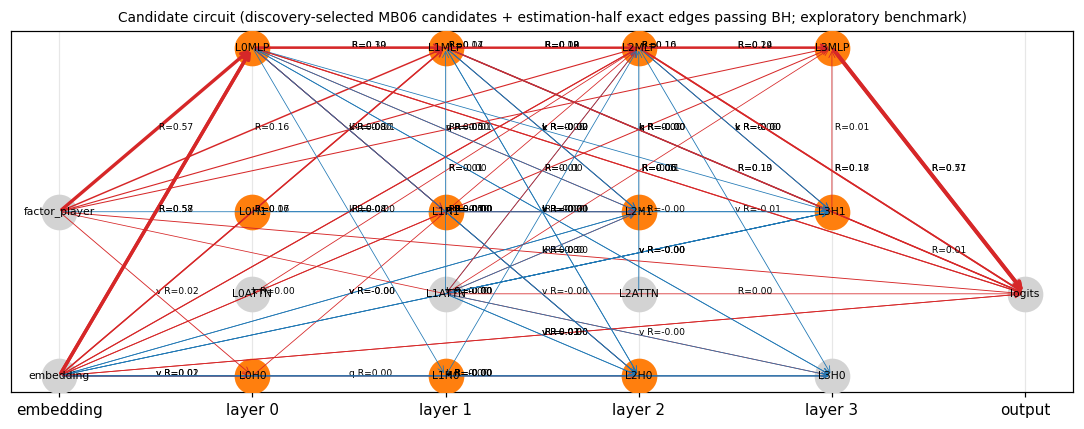

In [10]:
def node_position(name):
    if name in ("factor_player", "embedding"):
        return (0, 0 if name == "embedding" else 1)
    if name == "logits":
        return (N_LAYERS + 1, 0.5)
    base = name.split(".")[0]
    kind, layer, head = circuits.parse(base)
    y = {"head": head if head is not None else 0, "attn": 0.5, "mlp": N_HEADS}[kind]
    return (layer + 1, y)

fig, axis = plt.subplots(figsize=(10, 4))
nodes = set(circuit["components"]) | {"logits"}
for edge in circuit["edges"]:
    nodes |= {edge["sender"], edge["receiver"].split(".")[0]}
for node in nodes:
    x, y = node_position(node)
    axis.scatter(x, y, s=500, color="tab:orange" if node in circuit["components"] else "lightgrey", zorder=3)
    axis.annotate(node, (x, y), ha="center", va="center", fontsize=7, zorder=4)
for edge in circuit["edges"]:
    start = node_position(edge["sender"]); end = node_position(edge["receiver"].split(".")[0])
    axis.annotate("", xy=end, xytext=start, arrowprops=dict(arrowstyle="->", lw=0.5 + 3 * min(abs(edge["R"]), 1),
                                                            color="tab:red" if edge["R"] > 0 else "tab:blue"))
    axis.annotate(f"{edge['receiver'].split('.')[-1] if '.' in edge['receiver'] else ''} R={edge['R']:.2f}",
                  ((start[0] + end[0]) / 2, (start[1] + end[1]) / 2), fontsize=6)
axis.set_xticks(range(N_LAYERS + 2)); axis.set_xticklabels(["embedding"] + [f"layer {l}" for l in range(N_LAYERS)] + ["output"])
axis.set_yticks([]); axis.set_title(f"Candidate circuit ({circuit['source']})", fontsize=9)
plt.tight_layout(); plt.savefig(OUT / "figures" / "MB10_circuit.png", bbox_inches="tight"); plt.show()

**How to read.** Orange nodes are circuit components (grey nodes: receivers outside the circuit); arrows are edges passing Benjamini–Hochberg, labelled with the receiver side (q, k, v) and pooled recovery R; arrow width grows with |R|, red for R > 0. Hypothesis H3 (the player steers where later heads look) predicts passing edges into query inputs; H4 (late combination) predicts edges into the MLPs or heads of the last layers.

**Researcher interpretation** *(written by the researcher after reading the numbers above; the code never writes these words)*

- What was tested:
- Why it was tested:
- What was observed:
- What the result supports:
- What it contradicts:
- Alternative explanations that remain:
- What it does not establish:
- Evidence label (Observed / Supported / Strong causal evidence / Hypothesized):

In [11]:
mi_setup.save_json(OUT / "results" / "MB10_summary.json", {
    "senders": SENDERS, "edges_screened": int(len(screen)), "edges_tested_exactly": int(len(exact_edges)),
    "screen": screen.to_dict(orient="records") if len(screen) else [],
    "edges": edge_summary.to_dict(orient="records") if len(edge_summary) else [],
    "completeness": completeness.to_dict(orient="records") if len(completeness) else [],
    "circuit": circuit, "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"results/MB10_summary.json": OUT / "results" / "MB10_summary.json"})
fingerprint.register(REGISTRY, {"notebook": "MB10", "experiment": "E18 path patching (exhaustive screen + exact)",
                                "seed": PRIMARY_SEED, "edges_screened": int(len(screen)),
                                "edges_tested": int(len(exact_edges)),
                                "completeness_edges": int(len(completeness)),
                                "circuit_components": circuit["components"], "circuit_source": circuit["source"],
                                "run_mode": RUN_MODE})
print("registered")

registered


## R. Corrected first-order screen and everything that depends on it (REPAIR 2026-10-04)

**What was wrong (F01).** `receiver_gradients` replaced each receiver's read of the residual stream by
`value.detach().requires_grad_(True)`. The read for the logits (`final_resid`) is the whole residual stream, so detaching it
cut every upstream receiver off from Δ. Their gradients were `None` and were silently returned as zeros.

**What the screen is supposed to compute.** For an edge sender *s* → receiver *r* (Syed et al. 2023): the sender's
clean-minus-corrupted output difference, dotted with ∂Δ/∂(the residual copy that *r* alone reads), evaluated in the
corrupted run with everything downstream of *r* computed normally. The repaired function gives every receiver its own
`clone()` of the residual (still connected upstream, read only by that receiver) and calls `retain_grad()` on it; it raises
instead of returning zeros if a receiver receives no gradient. The screen is still a first-order estimate. It only ranks
edges; every promoted edge is patched exactly.

**What is re-run.** R1 checks the repaired gradients against finite differences on this model. R2 re-runs the screen.
R3 compares it with the exact patches already measured above. R4 patches exactly the edges the corrected screen selects,
under the same rule and budget as Section 4. R5 reruns the completeness check, and R6 records a corrected circuit file.
**Nothing here overwrites** `MB10_edge_screen.csv`, `MB10_edges.csv`, `MB10_completeness.csv` or `config/circuit.json`.

In [12]:
import importlib
try:
    import mi_src.scrub as scrub
    import mi_src.steering as steering
    import mi_src.context_edits as context_edits
    import mi_src.graph as graph
except ModuleNotFoundError as error:
    raise RuntimeError("BLOCKED: the repaired modules (scrub, steering, context_edits, graph) are missing. Run "
                       "MB07R_repaired_sources_and_regression_tests.ipynb, then restart the kernel.") from error
for module in [hooks, mi_metrics, circuits, scrub, steering, context_edits, graph]:
    importlib.reload(module)
for module in [circuits, mi_metrics, scrub, steering, context_edits, graph]:
    if getattr(module, "REPAIR_VERSION", None) != "2026-10-04":
        raise RuntimeError(f"BLOCKED: {module.__name__} on disk is not the repaired 2026-10-04 version. Re-run the repaired "
                           "%%writefile cells (MB02 for mi_metrics, MB07 for circuits, MB07R for the new modules), then restart.")
print("repaired modules loaded:", [m.__name__ for m in [circuits, mi_metrics, scrub, steering, context_edits, graph]])

# R1. Do the repaired gradients equal finite differences at INTERNAL receivers on SEL-4L? (float64 copy, one batch)
import copy as _copy
check_table = estimation.iloc[:32].reset_index(drop=True)
_, check_inputs, check_positions, check_ctx, check_id = next(mi_setup.event_batches(bundle, val_view, check_table, len(check_table)))
model64 = _copy.deepcopy(MODEL).double()
inputs64 = {k: (v.double() if v.is_floating_point() else v) for k, v in check_inputs.items()}
corrupted64 = interventions.remove_feature(inputs64, IDENTITY, check_positions)
check_gradients = circuits.receiver_gradients(model64, corrupted64, check_positions, check_ctx, check_id, RECEIVERS)
generator = torch.Generator().manual_seed(0)
gradient_check = []
for site, gradient in check_gradients.items():
    direction = torch.randn(gradient.shape, generator=generator, dtype=torch.float64).to(gradient.device)
    def total(eps):
        with torch.no_grad():
            logits, _ = hooks.forward(model64, corrupted64, replace={site: hooks.add_at(eps * direction)})
        return float(mi_metrics.delta(mi_metrics.at_target(logits, check_positions), check_ctx, check_id).sum())
    numeric = (total(1e-5) - total(-1e-5)) / 2e-5
    analytic = float((gradient * direction).sum())
    gradient_check.append({"receiver site": site, "finite difference": numeric, "repaired gradient": analytic,
                           "relative error": abs(numeric - analytic) / max(abs(numeric), 1e-9),
                           "|gradient| sum": float(gradient.abs().sum())})
gradient_check = pd.DataFrame(gradient_check)
gradient_check.to_csv(OUT / "results" / "MB10_gradient_check_corrected.csv", index=False)
print(gradient_check.round(6).to_string(index=False))
assert gradient_check["relative error"].max() < 1e-4, "BLOCKED: repaired gradients disagree with finite differences on SEL-4L"

repaired modules loaded: ['mi_src.circuits', 'mi_src.mi_metrics', 'mi_src.scrub', 'mi_src.steering', 'mi_src.context_edits', 'mi_src.graph']


receiver site  finite difference  repaired gradient  relative error  |gradient| sum
attn_in_q_0.0         -14.971429         -14.971429             0.0      413.676817
attn_in_k_0.0           5.954555           5.954555             0.0     1185.680138
attn_in_v_0.0         -15.271904         -15.271904             0.0     1804.160198
attn_in_q_0.1         -16.294180         -16.294180             0.0      465.101049
attn_in_k_0.1         -27.431834         -27.431834             0.0     1213.674792
attn_in_v_0.1           3.779524           3.779524             0.0     1633.941143
     mlp_in_0         130.451698         130.451699             0.0     7618.508824
attn_in_q_1.0          -2.423321          -2.423321             0.0      196.250246
attn_in_k_1.0           4.396517           4.396517             0.0      362.412481
attn_in_v_1.0          -8.659108          -8.659108             0.0      729.724436
attn_in_q_1.1           6.001617           6.001617             0.0      279

In [13]:
# R2. Corrected screen: identical to Section 3 except for the gradient function.
def run_screen(gradient_function):
    blocks = []
    for contrast, offsets in CONTRAST_OFFSETS.items():
        table = discovery if contrast != "context" else discovery[discovery["donor_window"].notna()].reset_index(drop=True)
        if contrast == "context":
            table["donor_window"] = table["donor_window"].astype(int)
        if len(table) == 0:
            continue
        match_codes, match_index = np.unique(table["match_id"].to_numpy(), return_inverse=True)
        edges = edge_list[edge_list.contrast == contrast].reset_index(drop=True)
        key_to_row = {(e.sender, e.offset, e.receiver): i for i, e in enumerate(edges.itertuples())}
        score_totals = np.zeros((len(edges), len(match_codes)))
        weight_totals = np.zeros(len(match_codes))
        sender_sites = sorted({site for sender in SENDERS for site in circuits.sender_sites(sender)})
        for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
            chunk = table.iloc[part]
            corrupted = corrupted_inputs(contrast, inputs, positions, chunk)
            clean_logits, clean_cache = hooks.forward(MODEL, inputs, capture=sender_sites)
            corrupt_logits, corrupt_cache = hooks.forward(MODEL, corrupted, capture=sender_sites)
            m_clean = mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
            m_corrupt = mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)
            difference_of_event = m_clean - m_corrupt
            sign = torch.as_tensor(np.sign(difference_of_event), dtype=torch.float32, device=DEVICE)
            gradients = gradient_function(MODEL, corrupted, positions, a_ctx, a_id, RECEIVERS)
            differences = {sender: circuits.sender_difference(MODEL, clean_cache, corrupt_cache, sender) for sender in SENDERS}
            rows_index = torch.arange(len(positions), device=DEVICE)
            batch_matches = match_index[part]
            for offset in offsets:
                at = positions + offset
                n_positions = inputs["zone"].shape[1]
                valid = (at >= 0) & (at < n_positions)
                safe = torch.clamp(at, 0, n_positions - 1)
                sender_stack = torch.stack([differences[s][rows_index, safe] for s in SENDERS])
                grad_stack = torch.stack([gradients[RECEIVER_SITE[r]][rows_index, safe] for r in RECEIVERS])
                scores = torch.einsum("sbd,rbd->srb", sender_stack, grad_stack)
                scores = (scores * sign.unsqueeze(0).unsqueeze(0) * valid.float().unsqueeze(0).unsqueeze(0)).cpu().numpy()
                for s_index, sender in enumerate(SENDERS):
                    for r_index, receiver in enumerate(RECEIVERS):
                        row = key_to_row.get((sender, offset, receiver))
                        if row is not None:
                            np.add.at(score_totals[row], batch_matches, scores[s_index, r_index])
            np.add.at(weight_totals, batch_matches, np.abs(difference_of_event))
        counts = np.bincount(match_index, minlength=len(match_codes)).astype(float)
        mean, low, high, draws = match_bootstrap_ratio(score_totals, np.tile(counts, (len(edges), 1)), N_BOOT)
        below = (np.sum(draws <= 0, axis=1) + 1) / (draws.shape[1] + 1)
        above = (np.sum(draws >= 0, axis=1) + 1) / (draws.shape[1] + 1)
        pvalues = np.minimum(1.0, 2 * np.minimum(below, above))
        reject, adjusted = mi_metrics.benjamini_hochberg(pvalues, 0.05)
        block = edges.copy()
        block["EAP mean"], block["EAP CI low"], block["EAP CI high"] = mean, low, high
        block["EAP pooled R (first order)"] = score_totals.sum(1) / weight_totals.sum() if weight_totals.sum() else np.nan
        block["EAP p"], block["EAP q"], block["EAP passes BH"] = pvalues, adjusted, reject
        block["n"] = len(table)
        blocks.append(block)
    return pd.concat(blocks, ignore_index=True) if blocks else pd.DataFrame()


start = time.time()
screen_corrected = screen.copy()  # Section 3 already uses the repaired gradient; no duplicate model passes.
print(f"corrected screen done in {time.time() - start:.0f} s")
screen_corrected.to_csv(OUT / "results" / "MB10_edge_screen_corrected.csv", index=False)
fingerprint.record_files(MANIFEST, {"results/MB10_edge_screen_corrected.csv": OUT / "results" / "MB10_edge_screen_corrected.csv"})
internal = lambda frame: frame[frame["receiver"] != "logits"]
comparison = pd.DataFrame([{"screen": name, "edges": len(frame), "internal-receiver edges": len(internal(frame)),
                            "internal edges with EAP mean exactly 0": int((internal(frame)["EAP mean"] == 0).sum()),
                            "edges passing BH": int(frame["EAP passes BH"].sum()),
                            "internal edges passing BH": int(internal(frame)["EAP passes BH"].sum())}
                           for name, frame in [("first corrected discovery screen", screen), ("corrected", screen_corrected)]])
print(comparison.to_string(index=False))

corrected screen done in 0 s
                          screen  edges  internal-receiver edges  internal edges with EAP mean exactly 0  edges passing BH  internal edges passing BH
first corrected discovery screen   4048                     4012                                     739               237                        223
                       corrected   4048                     4012                                     739               237                        223


In [14]:
# R3. Corrected screen vs the EXACT patches already measured in Section 4 (those exact values were never affected by F01).
tested_original = edge_summary[edge_summary["kind"] == "tested"] if len(edge_summary) else pd.DataFrame()
calibration_rows = []
for name, frame in [("original screen", screen), ("corrected screen", screen_corrected)]:
    merged = tested_original.merge(frame, on=["contrast", "sender", "offset", "receiver"], how="inner")
    for subset, block in [("all exactly tested edges", merged), ("internal receivers only", merged[merged["receiver"] != "logits"])]:
        calibration_rows.append({"screen": name, "edges": subset, "n": len(block),
                                 "Spearman(EAP mean, exact mean aligned change)":
                                     mi_metrics.spearman(block["EAP mean"], block["mean aligned change"]) if len(block) > 2 and block["EAP mean"].std() > 0 else np.nan})
screen_calibration = pd.DataFrame(calibration_rows)
screen_calibration.to_csv(OUT / "results" / "MB10_screen_calibration_corrected.csv", index=False)
print(screen_calibration.round(3).to_string(index=False))
print("A first-order score need not rank exactly like the exact patch; the comparison is reported, not assumed.")

          screen                    edges   n  Spearman(EAP mean, exact mean aligned change)
 original screen all exactly tested edges 624                                          0.510
 original screen  internal receivers only 592                                          0.477
corrected screen all exactly tested edges 624                                          0.510
corrected screen  internal receivers only 592                                          0.477
A first-order score need not rank exactly like the exact patch; the comparison is reported, not assumed.


In [15]:
# R4. Exact path patching of the edges the CORRECTED screen selects (same rule and budget as Section 4).
def select_edges(frame):
    chosen = []
    for contrast in CONTRAST_OFFSETS:
        block = frame[frame.contrast == contrast]
        required = block[block["sender_is_MB06_candidate"]]
        optional = block[~block["sender_is_MB06_candidate"]]
        optional = optional.reindex(optional["EAP mean"].abs().sort_values(ascending=False).index)
        chosen.append(pd.concat([required, optional.head(EXACT_EDGE_BUDGET)]))
    return pd.concat(chosen, ignore_index=True) if chosen else pd.DataFrame()


def exact_patch(chosen, seed=0):
    selected_senders = {e.sender for e in chosen.itertuples()}
    rng = np.random.default_rng(seed)
    controls_for = {}
    for edge in chosen.itertuples():
        if edge.sender in ("factor_player", "embedding"):
            continue
        kind, layer, _ = circuits.parse(edge.sender)
        pool = [c for c in ALL_COMPONENTS if c not in selected_senders and circuits.parse(c)[0] == kind
                and edge.receiver in circuits.receivers_after(c, N_LAYERS, N_HEADS)]
        options = [c for c in pool if circuits.parse(c)[1] == layer] or pool
        if options:
            controls_for[(edge.contrast, edge.sender, edge.offset, edge.receiver)] = str(rng.choice(options))
    records = []
    with torch.no_grad():
        for contrast in CONTRAST_OFFSETS:
            edges = chosen[chosen.contrast == contrast]
            if len(edges) == 0:
                continue
            table = estimation if contrast != "context" else estimation[estimation["donor_window"].notna()].reset_index(drop=True)
            if contrast == "context":
                table["donor_window"] = table["donor_window"].astype(int)
            needed = set()
            for sender in set(edges["sender"]) | {v for k, v in controls_for.items() if k[0] == contrast}:
                needed |= set(circuits.sender_sites(sender))
            for part, inputs, positions, a_ctx, a_id in mi_setup.event_batches(bundle, val_view, table, BATCH):
                chunk = table.iloc[part]
                corrupted = corrupted_inputs(contrast, inputs, positions, chunk)
                clean_logits, clean_cache = hooks.forward(MODEL, inputs, capture=sorted(needed))
                corrupt_logits, corrupt_cache = hooks.forward(MODEL, corrupted, capture=sorted(needed))
                m_clean = mi_metrics.delta(mi_metrics.at_target(clean_logits, positions), a_ctx, a_id)
                m_corrupt = mi_metrics.delta(mi_metrics.at_target(corrupt_logits, positions), a_ctx, a_id)
                for edge in edges.itertuples():
                    base = {"contrast": contrast, "sender": edge.sender, "offset": int(edge.offset), "receiver": edge.receiver,
                            "sender_is_MB06_candidate": bool(edge.sender_is_MB06_candidate),
                            "match_id": chunk["match_id"].to_numpy(), "m_clean": m_clean, "m_corrupt": m_corrupt}
                    difference = circuits.only_at(circuits.sender_difference(MODEL, clean_cache, corrupt_cache, edge.sender),
                                                  positions + int(edge.offset))
                    records.append(pd.DataFrame({**base, "kind": "tested",
                                                 "m_patched": circuits.path_patch(MODEL, corrupted, difference, edge.receiver, positions, a_ctx, a_id)}))
                    control = controls_for.get((contrast, edge.sender, int(edge.offset), edge.receiver))
                    if control is not None:
                        difference = circuits.only_at(circuits.sender_difference(MODEL, clean_cache, corrupt_cache, control),
                                                      positions + int(edge.offset))
                        records.append(pd.DataFrame({**base, "kind": f"control ({control})",
                                                     "m_patched": circuits.path_patch(MODEL, corrupted, difference, edge.receiver, positions, a_ctx, a_id)}))
    frame = pd.concat(records, ignore_index=True) if records else pd.DataFrame()
    if len(frame):
        frame["raw_change"] = frame["m_patched"] - frame["m_corrupt"]
        frame["aligned_change"] = mi_metrics.aligned(frame["raw_change"], frame["m_clean"] - frame["m_corrupt"])
    return frame


def summarise_edges(frame):
    rows = []
    keys = ["contrast", "sender", "offset", "receiver", "sender_is_MB06_candidate", "kind"]
    for (contrast, sender, offset, receiver, is_candidate, kind), group in frame.groupby(keys, sort=False):
        raw = mi_metrics.summarise(group["aligned_change"], group["match_id"], N_BOOT)
        pooled = mi_metrics.pooled_recovery(group["raw_change"], group["m_clean"] - group["m_corrupt"], group["match_id"], N_BOOT)
        rows.append({"contrast": contrast, "sender": sender, "offset": offset, "receiver": receiver,
                     "sender_is_MB06_candidate": is_candidate, "kind": "tested" if kind == "tested" else "control",
                     "control sender": None if kind == "tested" else kind[9:-1], "R": pooled["recovery"],
                     "R CI low": pooled["ci_low"], "R CI high": pooled["ci_high"], "mean aligned change": raw["mean"],
                     "CI low": raw["ci_low"], "CI high": raw["ci_high"],
                     "p": mi_metrics.bootstrap_pvalue(group["aligned_change"], group["match_id"], N_BOOT), "n": raw["n"]})
    out = pd.DataFrame(rows)
    tested = out["kind"] == "tested"
    reject, adjusted = mi_metrics.benjamini_hochberg(out.loc[tested, "p"].to_numpy(), 0.05)
    out.loc[tested, "q"] = adjusted
    out.loc[tested, "passes BH (q < 0.05)"] = reject
    return out


exact_edges_corrected = select_edges(screen_corrected) if len(screen_corrected) else pd.DataFrame()
start = time.time()
if len(exact_edges_corrected):
    pd.testing.assert_frame_equal(exact_edges[["contrast", "sender", "offset", "receiver"]].reset_index(drop=True), exact_edges_corrected[["contrast", "sender", "offset", "receiver"]].reset_index(drop=True))
paths_corrected = paths_frame.copy()  # Identical selection and deterministic controls; reuse fresh exact measurements.
print(f"exact path patching of {len(exact_edges_corrected)} corrected-screen edges done in {time.time() - start:.0f} s "
      f"({int(exact_edges_corrected['sender_is_MB06_candidate'].sum())} candidate-sender edges, "
      f"{int((~exact_edges_corrected['sender_is_MB06_candidate']).sum())} added by the corrected screen)")
edge_summary_corrected = summarise_edges(paths_corrected) if len(paths_corrected) else pd.DataFrame()
paths_corrected.to_parquet(OUT / "results" / "MB10_paths_corrected.parquet", index=False)
edge_summary_corrected.to_csv(OUT / "results" / "MB10_edges_corrected.csv", index=False)
fingerprint.record_files(MANIFEST, {"results/MB10_edges_corrected.csv": OUT / "results" / "MB10_edges_corrected.csv"})

exact path patching of 624 corrected-screen edges done in 0 s (481 candidate-sender edges, 143 added by the corrected screen)


{'artifacts/conflict/conflict_set.parquet': {'path': 'artifacts/conflict/conflict_set.parquet',
  'bytes': 1735548,
  'sha256': '19d6197298f38803450ba3befbc0e1b744b6ab900eecb0f6374783c4cf2263b3',
  'recorded_at': '2026-10-05T17:22:56.743259+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_128_64_seed0.pt',
  'bytes': 330757,
  'sha256': '590fbc131586f5297fcd9ddfcdf7f2e1c503cf13e9f584142a5c31a10a79339c',
  'recorded_at': '2026-10-05T17:22:56.743711+00:00'},
 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt': {'path': 'artifacts/conflict/identity_audit/id_mlp_512_512_256_seed0.pt',
  'bytes': 2280753,
  'sha256': 'eab81928ab7743ddbe2cbdb1dc60d5b584408386e896705115145e7c8a6d62a2',
  'recorded_at': '2026-10-05T17:22:56.746435+00:00'},
 'artifacts/conflict/predictions/test_probs.parquet': {'path': 'artifacts/conflict/predictions/test_probs.parquet',
  'bytes': 7982855,
  'sha256': 'd21c146acd76ee17cb82670b

In [16]:
# R5. Corrected completeness check, and whether the pre-registered candidate edges keep their BH status.
tested_corrected = edge_summary_corrected[edge_summary_corrected["kind"] == "tested"]
completeness_corrected = tested_corrected[(~tested_corrected["sender_is_MB06_candidate"]) & (tested_corrected["passes BH (q < 0.05)"] == True)]
completeness_corrected.to_csv(OUT / "results" / "MB10_completeness_corrected.csv", index=False)
print(f"non-candidate-sender edges passing BH: original {len(completeness)} | corrected {len(completeness_corrected)}")
if len(completeness_corrected):
    print(completeness_corrected[["contrast", "sender", "offset", "receiver", "R", "R CI low", "R CI high", "q"]].round(4).to_string(index=False))
key = ["contrast", "sender", "offset", "receiver"]
candidate_status = tested_original[tested_original["sender_is_MB06_candidate"]][key + ["R", "q", "passes BH (q < 0.05)"]].merge(
    tested_corrected[tested_corrected["sender_is_MB06_candidate"]][key + ["R", "q", "passes BH (q < 0.05)"]],
    on=key, how="outer", suffixes=(" (original)", " (corrected)"))
candidate_status["R identical"] = np.isclose(candidate_status["R (original)"], candidate_status["R (corrected)"], atol=1e-9)
changed = candidate_status[candidate_status["passes BH (q < 0.05) (original)"] != candidate_status["passes BH (q < 0.05) (corrected)"]]
candidate_status.to_csv(OUT / "results" / "MB10_candidate_edge_status_corrected.csv", index=False)
print(f"candidate-sender edges: {len(candidate_status)} | exact R identical to the original run: {int(candidate_status['R identical'].sum())} "
      f"| BH decision changed by the different family size: {len(changed)}")
if len(changed):
    print(changed.round(4).to_string(index=False))

non-candidate-sender edges passing BH: original 18 | corrected 18
        contrast    sender  offset receiver       R  R CI low  R CI high      q
identity removal      L2H1       0    L2MLP -0.0093   -0.0204    -0.0036 0.0076
identity removal      L2H1       0   L3H1.k -0.0003   -0.0006    -0.0001 0.0076
         context    L3ATTN       0   logits  0.0097    0.0062     0.0121 0.0076
         context      L0H1       0    L1MLP  0.0016    0.0008     0.0028 0.0076
         context      L1H1       0    L1MLP  0.0057    0.0032     0.0079 0.0076
         context embedding      -1   L0H0.v -0.0097   -0.0143    -0.0053 0.0076
         context      L1H0       0    L3MLP  0.0028    0.0013     0.0052 0.0076
         context      L1H0       0   logits  0.0021    0.0005     0.0041 0.0492
         context     L1MLP      -1   L2H0.v  0.0022    0.0014     0.0029 0.0076
         context embedding      -1   L0H1.v -0.0070   -0.0110    -0.0033 0.0076
         context      L1H1       0    L2MLP  0.0030   

In [17]:
# R6. Corrected circuit record. config/circuit.json (pre-registered, locked downstream) is NOT touched.
passing_corrected = tested_corrected[(tested_corrected["passes BH (q < 0.05)"] == True) & (tested_corrected["sender_is_MB06_candidate"])]
extra_corrected = set()
for _, edge in completeness_corrected.iterrows():
    extra_corrected |= set(expand(edge["sender"]))
extra_corrected -= set(circuit["components"])
circuit_corrected = {
    "status": "REPAIRED 2026-10-04 (F01): edges and completeness from the corrected screen; NOT pre-registered; "
              "config/circuit.json remains the pre-registered circuit used by MB11-MB14 and MB12's lock",
    "components": sorted(circuit["components"]),
    "components_unchanged_from_circuit_json": True,
    "edges": [{k: (e[k].item() if hasattr(e[k], "item") else e[k]) for k in ["contrast", "sender", "offset", "receiver", "R", "R CI low", "R CI high", "q"]}
              for _, e in passing_corrected.iterrows()],
    "edge_semantics": "each edge passed an individual single-edge exact path patch; the set has not been validated jointly (see MB11 R2)",
    "completeness_only": {"components": sorted(extra_corrected), "edges": completeness_corrected.to_dict(orient="records")},
    "screened_edges": int(len(screen_corrected)), "exactly_tested_edges": int(len(exact_edges_corrected)),
    "written_at": fingerprint.now()}
corrected_path = OUT / "config" / "circuit_corrected_screen.json"
mi_setup.save_json(corrected_path, circuit_corrected)
mi_setup.save_json(OUT / "results" / "MB10_summary_corrected.json", {
    "gradient_check": gradient_check.to_dict(orient="records"), "screen_comparison": comparison.to_dict(orient="records"),
    "screen_calibration": screen_calibration.to_dict(orient="records"),
    "candidate_edge_status_changes": int(len(changed)), "completeness_original": int(len(completeness)),
    "completeness_corrected": int(len(completeness_corrected)), "circuit_corrected": circuit_corrected, "run_mode": RUN_MODE})
fingerprint.record_files(MANIFEST, {"config/circuit_corrected_screen.json": corrected_path,
                                    "results/MB10_summary_corrected.json": OUT / "results" / "MB10_summary_corrected.json"})
fingerprint.register(REGISTRY, {"notebook": "MB10", "experiment": "R: corrected EAP screen (F01) + dependent exact patching",
                                "seed": PRIMARY_SEED, "edges_screened": int(len(screen_corrected)),
                                "edges_tested": int(len(exact_edges_corrected)), "completeness_edges": int(len(completeness_corrected)),
                                "run_mode": RUN_MODE})
print(f"pre-registered edges passing BH: original {len(circuit['edges'])} | corrected family {len(circuit_corrected['edges'])}")
print(f"components only the corrected completeness check found: {sorted(extra_corrected)}")

pre-registered edges passing BH: original 96 | corrected family 96
components only the corrected completeness check found: ['L3H0']


**Reading Section R (fixed before the corrected numbers exist).**

* R1 must pass; otherwise nothing after it is read.
* The pre-registered **components** are unchanged by construction. If R5 reports candidate-sender edges whose BH decision
  changed, that change comes only from the different number of edges in the BH family. The exact values are identical.
  The exploratory candidate circuit stays `config/circuit.json`; the corrected record is a separate, non-pre-registered file.
* If the corrected completeness check finds non-candidate edges, that is a finding about the discovery procedure, as
  Section 5 states. It is not a licence to enlarge the exploratory candidate circuit, and it must not be read against MB12's test
  results, which were seen before this correction.
* A first-order screen ranks edges for exact testing; it is not evidence on its own.

**Researcher interpretation of Section R** *(to be written after reading the corrected numbers)*

- What was tested:
- What was observed:
- What it supports / contradicts:
- What it does not establish:

Surgical fixes R06–R07: optional edges are ranked on discovery matches without a low-resolution significance gate, frozen before exact estimation measurements, and tested with required edges as one fixed family. Completeness is limited to the stated exact-test budget; an untested edge is not evidence of absence. The same corrected gradient is used in both screening sections.